# Experiment 3: Synthetic Generalized Mixed-Variable Optimization

Evaluation of the **Generalized $(\mu, \lambda)$-Evolution Strategy** with synthetic benchmark functions combining all 6 variable types.


In [ ]:
from pathlib import Path
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is in sys.path
cwd = Path.cwd().resolve()
project_root = next(p for p in [cwd] + list(cwd.parents) if (p / "src").is_dir())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Force reload utils modules if cached in an active Jupyter session
import importlib
for mod_name in [
    "experiments.experiment_3.runners.plotting",
    "experiments.experiment_3.runners.runners",
    "experiments.experiment_3.runners.run_experiment_3",
]:
    if mod_name in sys.modules:
        importlib.reload(sys.modules[mod_name])

from src.es_model.config import ESConfig
from src.benchmarks.generalized_functions import GENERALIZED_BENCHMARKS
from experiments.experiment_3.runners.runners import (
    run_heterogeneous_benchmark_suite,
    load_heterogeneous_benchmark_suite,
    load_heterogeneous_dynamics_tracking,
    run_heterogeneous_dynamics_tracking,
    build_heterogeneous_summary_table,
)
from experiments.experiment_3.runners.plotting import (
    plot_heterogeneous_convergence,
    plot_heterogeneous_dynamics,
)

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Experiment Execution Configuration


In [ ]:
# Experiment execution parameters
MAX_EVALS = 20000
N_SEEDS = 40
print(f">>> Experiment Parameters: {MAX_EVALS:,} evaluations, {N_SEEDS} seeds")

# Generalized genome configuration testing all 6 variable types
CONFIG = ESConfig(
    mu=15,
    lam=100,
    n_real=5,
    n_count=3,
    n_binary=4,
    n_categorical=2,
    categorical_k=np.array([3, 4], dtype=np.int64),
    n_fuzzy=2,
    n_circular=2,
    circular_k=np.array([7, 12], dtype=np.int64),
    seed=42,
)

print(f"\nGeneralized ES Hyperparameters:")
print(f"  Survivors (mu): {CONFIG.mu}, Offspring (lambda): {CONFIG.lam}")
print(f"  Active Dimensions: Real={CONFIG.n_real}, Count={CONFIG.n_count}, Binary={CONFIG.n_binary}, Categorical={CONFIG.n_categorical} (k={list(CONFIG.categorical_k)}), Fuzzy={CONFIG.n_fuzzy} (x2 params: m, d), Circular={CONFIG.n_circular} (k={list(CONFIG.circular_k)})")
print(f"  Total Active Genome Dimensionality (n_total): {CONFIG.n_total}")

>>> Experiment Parameters: 20,000 evaluations, 40 seeds

Generalized ES Hyperparameters:
  Survivors (mu): 15, Offspring (lambda): 100
  Active Dimensions: Real=5, Count=3, Binary=4, Categorical=2 (k=[np.int64(3), np.int64(4)]), Fuzzy=2 (x2 params: m, d), Circular=2 (k=[np.int64(7), np.int64(12)])
  Total Active Genome Dimensionality (n_total): 20


## 2. Multi-Seed Optimization Execution

Executes the Generalized ES on all 4 synthetic benchmarks with random seeds:

In [ ]:
SEEDS = [42 + i * 101 for i in range(N_SEEDS)]
data_dir = os.path.join(str(project_root), "experiments", "experiment_3", "data")
FIGURES_DIR = os.path.join(str(project_root), "experiments", "experiment_3", "figures")

# User execution control:
# - Set RUN_SIMULATION = True to execute the full heterogeneous simulations from scratch (~5-10 min).
# - Set RUN_SIMULATION = False to load precomputed .npz results from data/.
RUN_SIMULATION = False

print(f">>> Experiment 3 Configuration: {N_SEEDS} seeds, {MAX_EVALS} evals | RUN_SIMULATION={RUN_SIMULATION}")

if RUN_SIMULATION:
    print(">>> RUN_SIMULATION=True: Running full heterogeneous benchmark suite from scratch...\n")
    results = run_heterogeneous_benchmark_suite(
        benchmarks=GENERALIZED_BENCHMARKS,
        config=CONFIG,
        seeds=SEEDS,
        max_evals=MAX_EVALS,
        data_dir=data_dir,
    )
else:
    print(f">>> RUN_SIMULATION=False: Loading precomputed benchmark traces from: {data_dir}")
    results = load_heterogeneous_benchmark_suite(data_dir, GENERALIZED_BENCHMARKS)
    if results is None:
        raise FileNotFoundError(f"Missing traces at {data_dir}/exp3_traces.npz. Set RUN_SIMULATION = True to run.")

>>> Experiment 3 Configuration: 40 seeds, 20000 evals | RUN_SIMULATION=False
>>> RUN_SIMULATION=False: Loading precomputed benchmark traces from: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\data


## 3. Convergence Curves (Fitness vs. Evaluations)

Plots the median fitness convergence curves across all random seeds. The shaded area represents the interquartile range (IQR, $[Q_1, Q_3]$).

Saved separate convergence figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_sphere_convergence.png


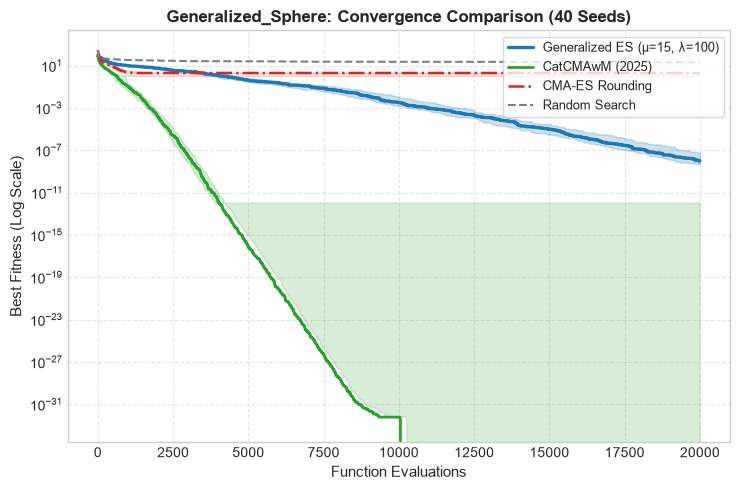

Saved separate convergence figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_rastrigin_convergence.png


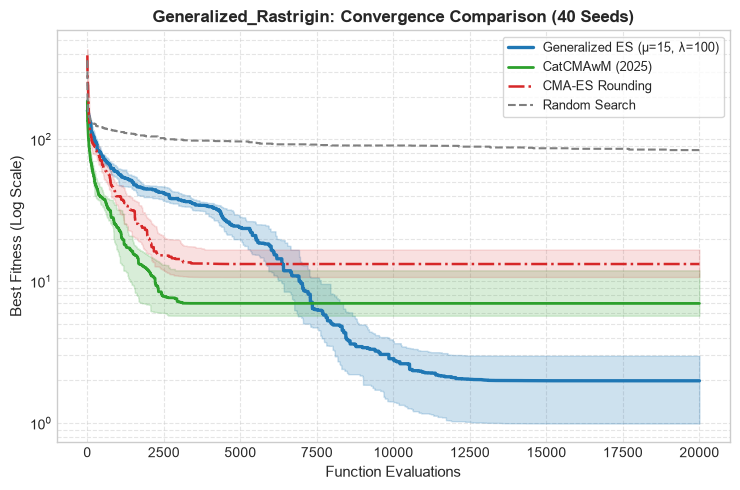

Saved separate convergence figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_coupled_convergence.png


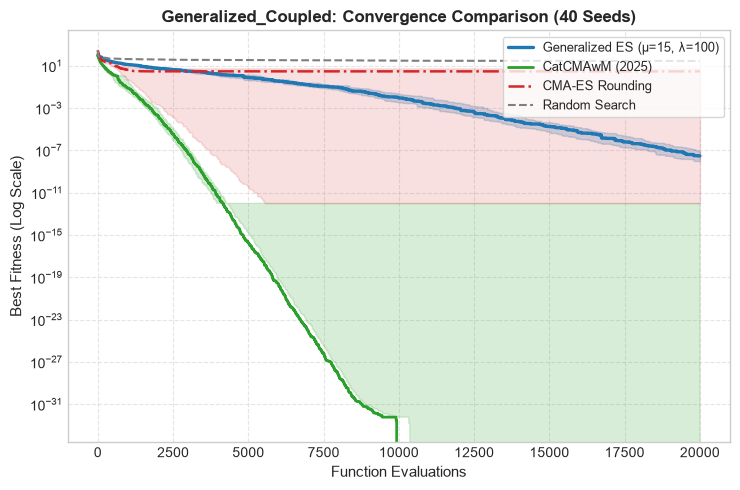

Saved separate convergence figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_multiplicative_convergence.png


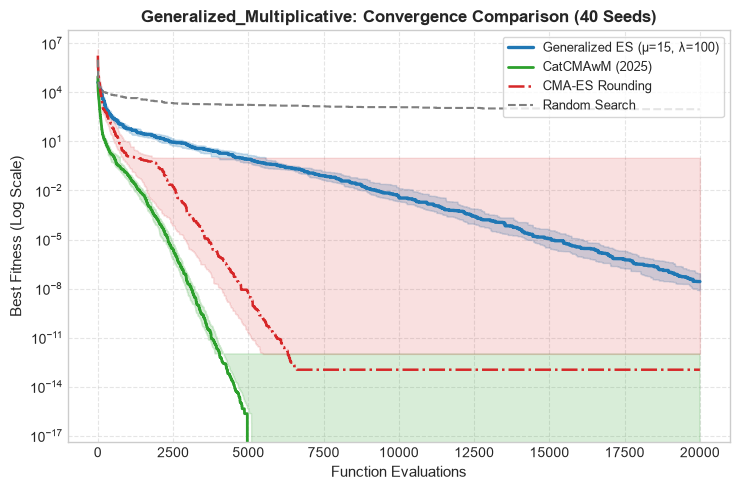

In [ ]:
plot_heterogeneous_convergence(
    results=results,
    max_evals=MAX_EVALS,
    config=CONFIG,
    n_seeds=N_SEEDS,
    save_dir=FIGURES_DIR,
)

## 4. Heterogeneous Variable & Strategy Dynamics (Multi-Seed Analysis)

Comprehensive 3-panel diagnostic tracking of all 6 decision variable types across all benchmark functions (Mean $\pm 1$ Std across all random seeds):
- **Panel A (Mutation Intensities & Step Sizes)**: Log-scale evolution of continuous and discrete step rates ($\sigma_{\text{real}}, \lambda_{\text{count}}, \sigma_{\text{fuzzy}}, \lambda_{\text{circular}}$).
- **Panel B (Probabilities & Mutation Rates)**: Bounded $[0, 1]$ metrics tracking binary bit-flip probability $p_{\text{flip}} = \sigma(\text{logit}_{\text{binary}})$ and categorical modular jump mutation probability $p_{\text{mut}} = \sigma(\text{logit}_{\text{cat}})$.
- **Panel C (Fitness Error Decomposition)**: Log-scale partial fitness contributions ($f_{\text{real}}, f_{\text{count}}, f_{\text{binary}}, f_{\text{cat}}, f_{\text{fuzzy}}, f_{\text{circular}}$) revealing the exact sequence and generation of resolution for each variable type.

>>> RUN_SIMULATION=False: Loading precomputed dynamics tracking from: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\data
  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_sphere_step_sizes.png


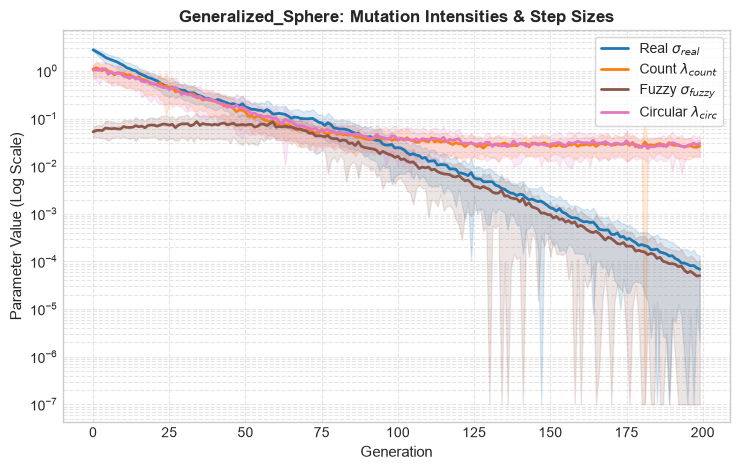

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_sphere_probabilities.png


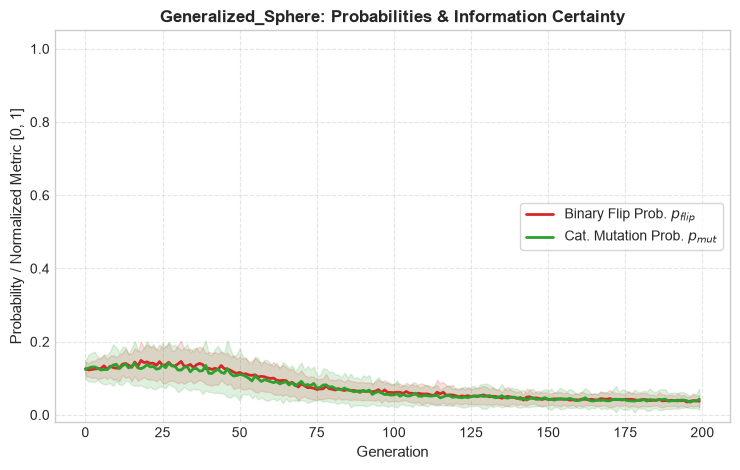

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_sphere_decomposition.png


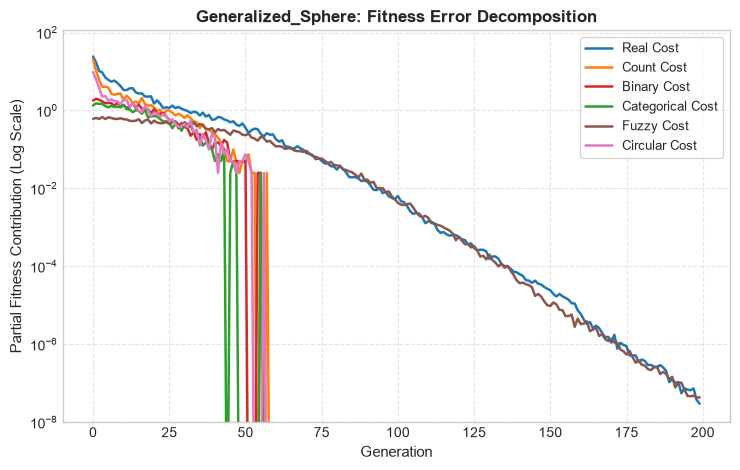

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_rastrigin_step_sizes.png


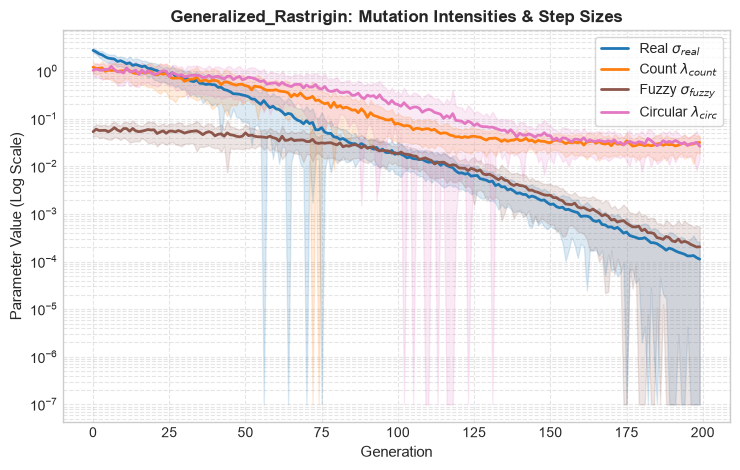

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_rastrigin_probabilities.png


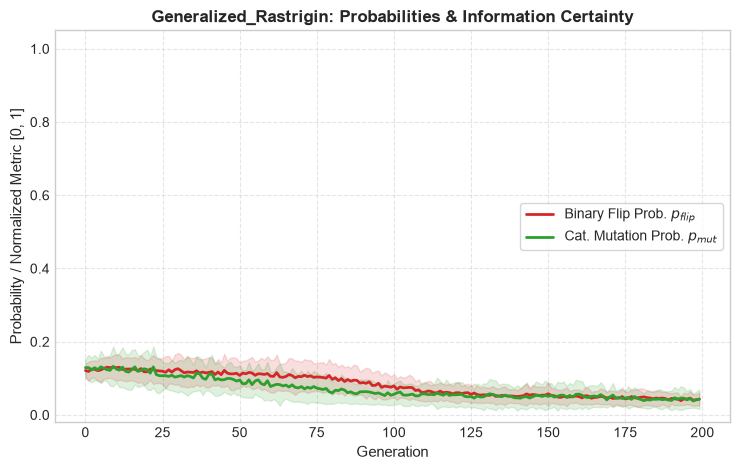

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_rastrigin_decomposition.png


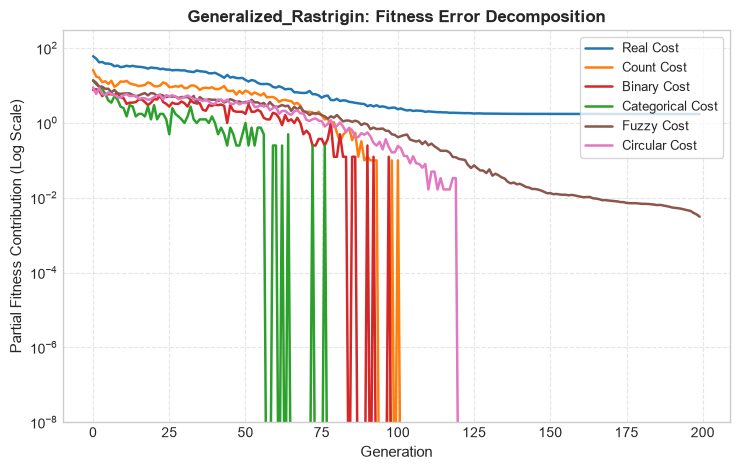

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_coupled_step_sizes.png


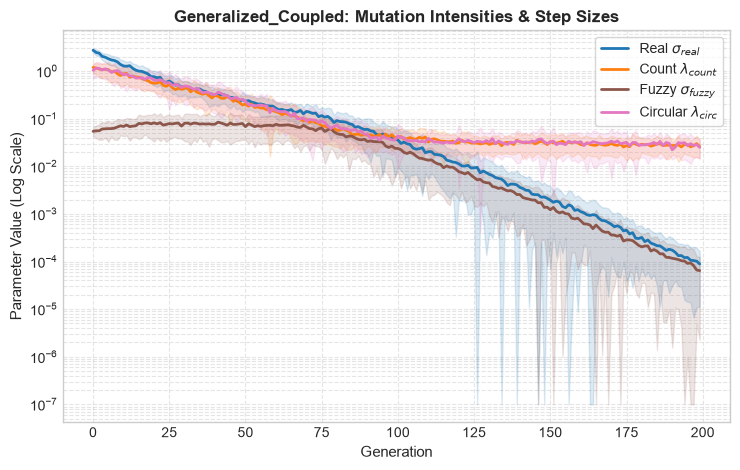

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_coupled_probabilities.png


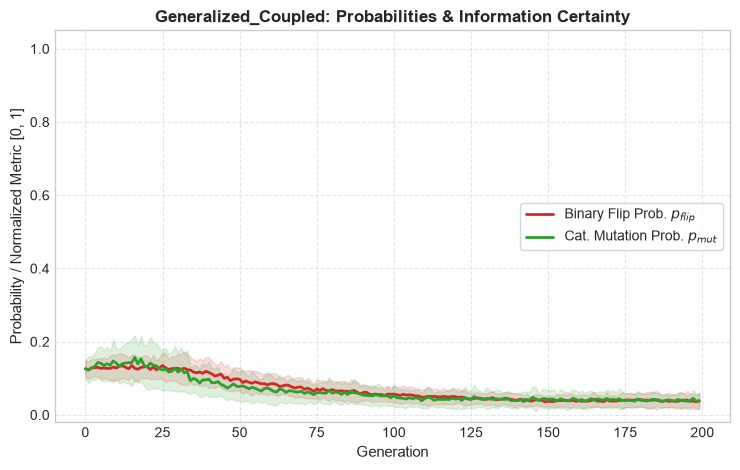

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_coupled_decomposition.png


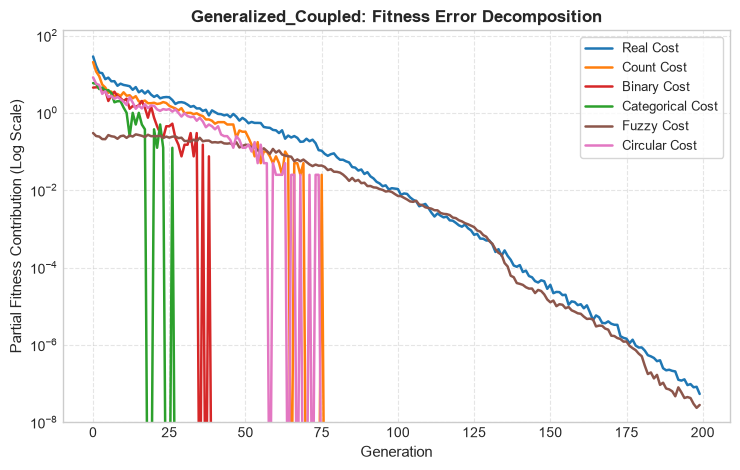

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_multiplicative_step_sizes.png


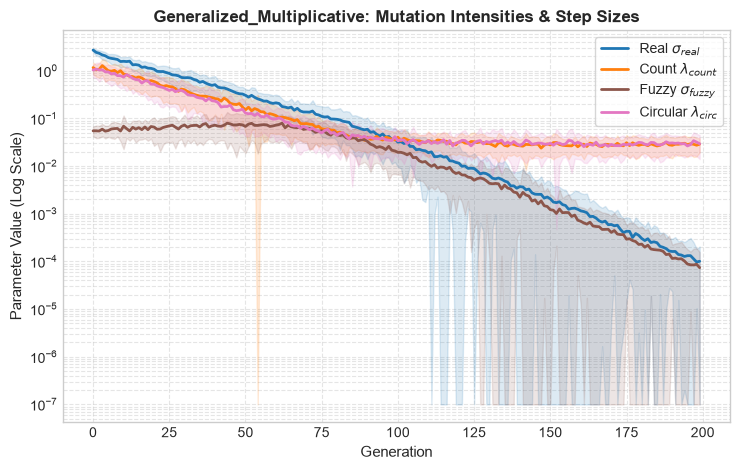

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_multiplicative_probabilities.png


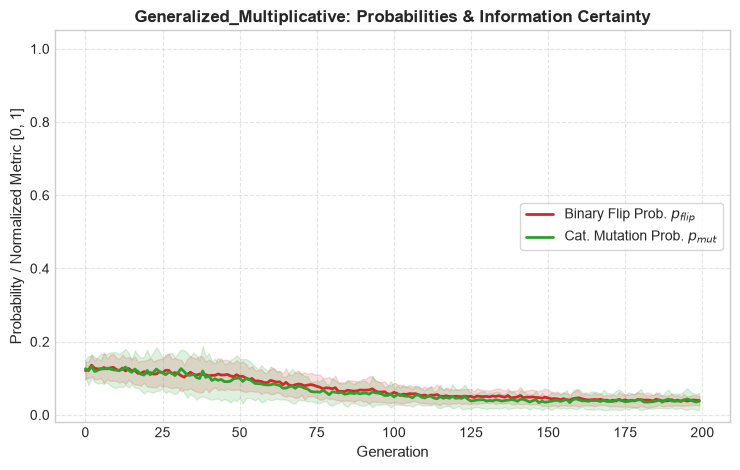

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\experiment_3\figures\exp3_generalized_multiplicative_decomposition.png


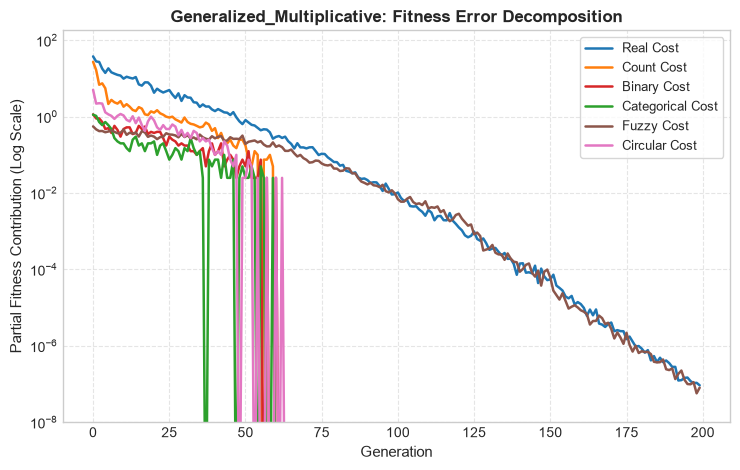

In [ ]:
if RUN_SIMULATION:
    print(">>> RUN_SIMULATION=True: Running dynamics tracking from scratch...\n")
    all_saved_data, bench_dynamics = run_heterogeneous_dynamics_tracking(
        benchmarks=GENERALIZED_BENCHMARKS,
        config=CONFIG,
        seeds=SEEDS,
        max_evals=MAX_EVALS,
        data_dir=data_dir,
    )
else:
    print(f">>> RUN_SIMULATION=False: Loading precomputed dynamics tracking from: {data_dir}")
    all_saved_data, bench_dynamics = load_heterogeneous_dynamics_tracking(data_dir, GENERALIZED_BENCHMARKS)
    if all_saved_data is None:
        raise FileNotFoundError(f"Missing dynamics at {data_dir}/exp3_strategy_dynamics.npz. Set RUN_SIMULATION = True to run.")

n_generations = MAX_EVALS // CONFIG.lam
for bench_name, bench_agg in bench_dynamics.items():
    plot_heterogeneous_dynamics(
        bench_name=bench_name,
        bench_agg=bench_agg,
        n_generations=n_generations,
        n_seeds=N_SEEDS,
        save_dir=FIGURES_DIR,
    )

## 5. Statistical Results Summary Table

In [ ]:
summary_df = build_heterogeneous_summary_table(
    results=results,
    seeds=SEEDS,
    max_evals=MAX_EVALS,
)

print("=" * 90)
print(f" EXPERIMENT 3 RESULTS SUMMARY ({N_SEEDS} Seeds | {MAX_EVALS} Max Evaluations)")
print("=" * 90)
if hasattr(summary_df, "to_string"):
    print(summary_df.to_string(index=False))
else:
    for row in summary_df:
        print(row)
print("=" * 90)

 EXPERIMENT 3 RESULTS SUMMARY (40 Seeds | 20000 Max Evaluations)
        Benchmark Function Mean Best Fitness      Std Dev Min (Best Run)
        Generalized_Sphere      6.501150e-08 1.362598e-07   7.891276e-10
     Generalized_Rastrigin      1.744432e+00 1.231932e+00   1.184947e-06
       Generalized_Coupled      1.008621e-07 2.200953e-07   4.582423e-10
Generalized_Multiplicative      1.344279e-07 3.076229e-07   1.354019e-09


## 6. Comparison with External Baselines

Compares Generalized ES performance against **Uniform Random Search**, **Continuous CMA-ES with Rounding**, and **CatCMA with Margin (CatCMAwM, 2025)** across all 4 heterogeneous benchmarks (*Sphere*, *Coupled*, *Rastrigin*, *Multiplicative*) (40 independent random seeds, 20,000 evaluations per seed).

Evaluates non-parametric two-sided paired Wilcoxon signed-rank significance tests with global step-down Holm-Bonferroni correction ($m = 12$ family-wise hypotheses at $\alpha = 0.05$):
- **W/T/L**: Wins / Ties / Losses for Generalized ES against the opponent across paired seeds.
- **W-stat**: Wilcoxon signed-rank test statistic ($W$).
- **r_rb**: Matched-pairs rank-biserial correlation effect size $r_{\text{rb}} \in [-1, +1]$ ($+1.0$ indicates complete dominance by GES).
- **p-raw / p-adj**: Raw asymptotic $p$-value and adjusted $p$-value after Holm-Bonferroni correction ($m = 12$).
- **Decision**: Significant superiority outcome at $\alpha = 0.05$.


In [7]:
import importlib
import experiments.experiment_3.runners.run_experiment_3 as exp3_runner
importlib.reload(exp3_runner)
from experiments.experiment_3.runners.run_experiment_3 import compute_wilcoxon_table_exp3

exp3_traces_file = os.path.join(data_dir, "exp3_traces.npz")
baseline_file = os.path.join(data_dir, "random_search_results.json")

print("=" * 120)
print(f"{'Benchmark':<28} | {'Opponent':<18} | {'W/T/L':<8} | {'W-stat':<8} | {'r_rb':<7} | {'p-raw':<10} | {'p-adj':<10} | {'Decision'}")
print("=" * 120)
tests_exp3 = compute_wilcoxon_table_exp3(exp3_traces_file, baseline_file)
for bench_name, records in tests_exp3.items():
    for r in records:
        wtl = f"{r['wins']}/{r['ties']}/{r['losses']}"
        w_str = f"{r['w_stat']:.1f}" if not np.isnan(r['w_stat']) else "NaN"
        r_val = r.get('r_biserial', 0.0)
        r_str = f"{r_val:+.3f}"
        p_r = f"{r['raw_p']:.3e}"
        p_a = f"{r['adj_p']:.3e}"
        print(f"{bench_name:<28} | {r['opponent']:<18} | {wtl:<8} | {w_str:<8} | {r_str:<7} | {p_r:<10} | {p_a:<10} | {r['decision']}")
print("=" * 120)

Benchmark                    | Opponent           | W/T/L    | W-stat   | r_rb    | p-raw      | p-adj      | Decision
Heterogeneous Sphere         | Random Search      | 40/0/0   | 0.0      | +1.000  | 1.819e-12  | 2.183e-11  | Generalized ES Wins
Heterogeneous Sphere         | CMA-ES Rounding    | 33/0/7   | 28.0     | +0.932  | 2.698e-09  | 8.093e-09  | Generalized ES Wins
Heterogeneous Sphere         | CatCMAwM (2025)    | 0/0/40   | 0.0      | -1.000  | 1.819e-12  | 2.183e-11  | Baseline Wins
Heterogeneous Coupled        | Random Search      | 40/0/0   | 0.0      | +1.000  | 1.819e-12  | 2.183e-11  | Generalized ES Wins
Heterogeneous Coupled        | CMA-ES Rounding    | 23/0/17  | 153.0    | +0.627  | 3.364e-04  | 6.729e-04  | Generalized ES Wins
Heterogeneous Coupled        | CatCMAwM (2025)    | 0/0/40   | 0.0      | -1.000  | 1.819e-12  | 2.183e-11  | Baseline Wins
Heterogeneous Rastrigin      | Random Search      | 40/0/0   | 0.0      | +1.000  | 1.819e-12  | 2.183e-11  | Gen